In [ ]:
# Importamos las librerías que utilizaremos
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

Librerías importadas correctamente.


# 1.- Preprocesamiento de Imagenes de Formularios Físicos

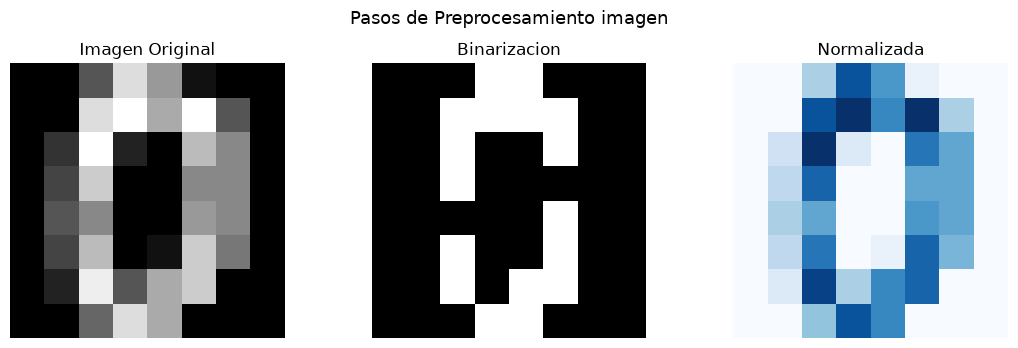

In [6]:
#Cargamos los dígitos de ejemplo
digitos=load_digits()
imagen_original=digitos.images[0]
umbral = 8
imagen_binaria=np.zeros(imagen_original.shape)

for fila in range(8):
    for col in range(8):
        if imagen_original[fila, col] > umbral:
            imagen_binaria[fila, col]=1
        else:
            imagen_binaria[fila, col]=0

#Normalizacin
imagen_normalizada = imagen_original / 16.0

plt.figure(figsize=(11, 3.5))
plt.subplot(1, 3, 1)
plt.imshow(imagen_original, cmap='gray')
plt.title("Imagen Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(imagen_binaria, cmap='gray')
plt.title("Binarizacion")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_normalizada, cmap='Blues')
plt.title("Normalizada")
plt.axis('off')

plt.suptitle("Pasos de Preprocesamiento imagen", fontsize=13)
plt.tight_layout()
plt.show()

# 2.- Cargamos del Dataset para entrenamiento y prueba.

In [ ]:
# Datos y etiquetas del 0 al 9
X=digitos.data
y=digitos.target

print("Total de imágenes en el dataset:", len(X))
print("Forma de cada imagen:", digitos.images[0].shape)

X=X / 16.0
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba=train_test_split(X, y, test_size=0.20, random_state=42)

print("Datos de entrenamiento:", len(X_entrenamiento))
print("Datos de prueba:", len(X_prueba))

Total de imágenes en el dataset: 1797
Forma de cada imagen: (8, 8)
Datos de entrenamiento: 1437
Datos de prueba: 360


# 3.- Implementacion de los Algoritmos de Machine Learning

In [ ]:
red=MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=300, random_state=42)
red.fit(X_entrenamiento, y_entrenamiento)

prediccion_red=red.predict(X_prueba)
acc_red=accuracy_score(y_prueba, prediccion_red)
print("1. Exactitud de la Red Neuronal:", round(acc_red * 100, 2), "%")

regresion=LogisticRegression(max_iter=1000, random_state=42)
regresion.fit(X_entrenamiento, y_entrenamiento)

prediccion_reg=regresion.predict(X_prueba)
acc_reg=accuracy_score(y_prueba, prediccion_reg)
print("2. Exactitud de la Regresión Logística:", round(acc_reg * 100, 2), "%")

kmeans=KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans.fit(X_entrenamiento)

pred_clusters=kmeans.predict(X_prueba)
pred_kmeans=np.zeros(len(pred_clusters))

for grupo in range(10):
    indices=np.where(kmeans.labels_==grupo)[0]
    if len(indices) > 0:
        digitos_en_grupo=y_entrenamiento[indices]
        valores, conteos=np.unique(digitos_en_grupo, return_counts=True)
        digito_mas_comun=valores[np.argmax(conteos)]
        pred_kmeans[pred_clusters==grupo]=digito_mas_comun

acc_kmeans=accuracy_score(y_prueba, pred_kmeans)
print("3. Exactitud de K-Means:", round(acc_kmeans * 100, 2), "%")

knn=KNeighborsClassifier(n_neighbors=3)
knn.fit(X_entrenamiento, y_entrenamiento)

pred_knn=knn.predict(X_prueba)
acc_knn=accuracy_score(y_prueba, pred_knn)
print("4. Exactitud de KNN:", round(acc_knn * 100, 2), "%")

1. Exactitud de la Red Neuronal: 97.22 %
2. Exactitud de la Regresión Logística: 96.67 %
3. Exactitud de K-Means: 80.28 %
4. Exactitud de KNN: 98.33 %


# 4.- Comparamos los resultados de los modelos

TABLA COMPARATIVA DE RENDIMIENTO
          Algoritmo  Exactitud (%)
                KNN          98.33
       Red Neuronal          97.22
Regresión Logistica          96.67
            K-Means          80.28


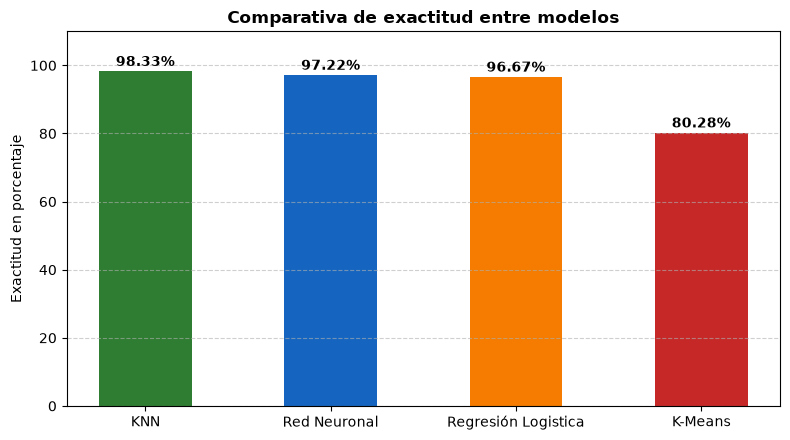

In [12]:
# Creamos una lista sencilla con los resultados
nombres=["Red Neuronal", "KNN", "Regresión Logistica", "K-Means"]
porcentajes = [
    round(acc_red * 100, 2),
    round(acc_knn * 100, 2),
    round(acc_reg * 100, 2),
    round(acc_kmeans * 100, 2)
]


tabla_comparativa=pd.DataFrame({
    "Algoritmo": nombres,
    "Exactitud (%)": porcentajes
})

# Ordenamos de mayor a menor
tabla_comparativa=tabla_comparativa.sort_values(by="Exactitud (%)", ascending=False)
print("TABLA COMPARATIVA DE RENDIMIENTO")
print(tabla_comparativa.to_string(index=False))

# Gráfico de barras de los resultados
plt.figure(figsize=(8, 4.5))
colores=['#2e7d32', '#1565c0', '#f57c00', '#c62828']
barras=plt.bar(tabla_comparativa["Algoritmo"], tabla_comparativa["Exactitud (%)"], color=colores, width=0.5)

for barra in barras:
    altura=barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, altura + 1.5, str(altura) + "%", ha='center', fontweight='bold')

plt.title("Comparativa de exactitud entre modelos", fontsize=12, fontweight='bold')
plt.ylabel("Exactitud en porcentaje")
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 5.- Matriz de confusion y reporte de metricas utilizando una red neuronal

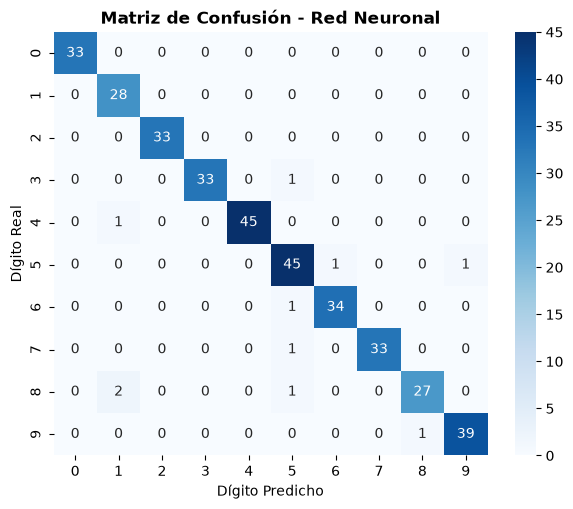

REPORTE FORMAL DE CLASIFICACION
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.90      1.00      0.95        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       1.00      0.98      0.99        46
           5       0.92      0.96      0.94        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.96      0.90      0.93        30
           9       0.97      0.97      0.97        40

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



In [13]:
# Calculamos la matriz de confusión
matriz = confusion_matrix(y_prueba , prediccion_red)

# La graficamos utilizando el mapa de calor
plt.figure(figsize=(7, 5.5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusión - Red Neuronal", fontsize=12, fontweight='bold')
plt.xlabel("Dígito Predicho")
plt.ylabel("Dígito Real")
plt.show()

# Imprimimos el reporte
print("REPORTE FORMAL DE CLASIFICACION")
print(classification_report(y_prueba, prediccion_red))

# 6. Resultados Visuales: Predicciones del Modelo en Formularios

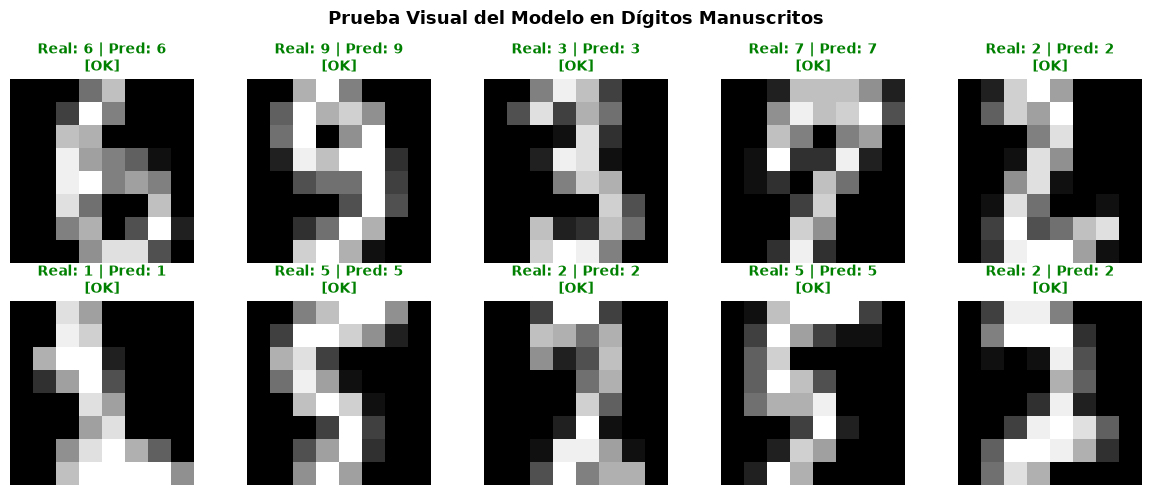

In [ ]:
# se muestra 10 ejemplos de prueba
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    
    # Reconstruimos la matriz de 8x8 para visualizar la imagen
    img = X_prueba[i].reshape(8, 8)
    plt.imshow(img, cmap='gray')
    
    real = y_prueba[i]
    predicho = prediccion_red[i]
    
    # Si acierta lo ponemos en verde
    if real == predicho:
        color_texto = 'green'
        resultado = "OK"
    else:
        color_texto = 'red'
        resultado = "ERROR"
        
    plt.title("Real: " + str(real) + " | Pred: " + str(predicho) + "\n[" + resultado + "]", 
              color=color_texto, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.suptitle("Prueba visual del modelo en digitos manuscritos", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 7.- Arquitectura de la red reuronal

* **Capa de Entrada:** 64 neuronas.
* **Primera Capa Oculta:** 64 neuronas con función de activación RELU.
* **Segunda Capa Oculta:** 32 neuronas con función de activación RELU.
* **Capa de Salida:** 10 neuronas.
* **Optimizador:** Adam.
* **Número de iteraciones:** 300 epocas.